# UCS420 – Assignment 10
## Heart Health Information Assistant (Even Roll Number)

**Objective:** Build a Python-based cognitive assistant that identifies heart-health query intent, retrieves relevant information, applies reasoning rules, and responds through an interactive interface.

**How to use:** Open this notebook in Google Colab and run the cells from top to bottom. The assistant is an educational demonstration, not a medical diagnosis tool.

## 1. Install and import required libraries

In [1]:
!pip -q install nltk scikit-learn seaborn matplotlib ipywidgets

In [2]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully.


## 2. Create a labelled corpus (64 queries, 8 intent categories)

In [3]:
data = {
    "diet_nutrition": [
        "What foods are good for heart health?",
        "Suggest a heart healthy diet plan.",
        "Which foods should I avoid to reduce cholesterol?",
        "Is eating oats good for the heart?",
        "How can I reduce salt in my daily meals?",
        "Are fruits and vegetables important for cardiovascular health?",
        "What is a low sodium diet?",
        "Does eating too much saturated fat affect the heart?"
    ],
    "physical_activity": [
        "How much exercise is good for the heart?",
        "Can walking improve cardiovascular fitness?",
        "Suggest safe exercises for a healthy heart.",
        "How many minutes should I walk every day?",
        "Is cycling beneficial for heart health?",
        "Can regular physical activity lower blood pressure?",
        "What warm up should I do before exercising?",
        "How can I start exercising after being inactive?"
    ],
    "blood_pressure": [
        "What does high blood pressure mean?",
        "How can I control hypertension naturally?",
        "What is a normal blood pressure reading?",
        "Why is monitoring blood pressure important?",
        "Can too much salt increase blood pressure?",
        "What are common risk factors for hypertension?",
        "How often should blood pressure be checked?",
        "What lifestyle changes help manage high blood pressure?"
    ],
    "coronary_disease": [
        "What is coronary artery disease?",
        "How does plaque build up in arteries?",
        "What are the risk factors for coronary heart disease?",
        "Can high cholesterol affect coronary arteries?",
        "How is coronary artery disease diagnosed?",
        "What is the difference between a heart attack and heart disease?",
        "How can I reduce my risk of coronary artery disease?",
        "Does smoking increase the risk of heart disease?"
    ],
    "symptom_information": [
        "What are common symptoms of heart problems?",
        "Why do some people feel palpitations?",
        "Can shortness of breath be related to the heart?",
        "What causes an irregular heartbeat?",
        "Is unusual tiredness sometimes linked to heart disease?",
        "What does chest discomfort mean?",
        "Can swollen ankles be related to heart conditions?",
        "What are warning signs that should be checked by a doctor?"
    ],
    "emergency_response": [
        "What should I do if someone may be having a heart attack?",
        "A person has severe chest pain and is sweating, what should I do?",
        "Someone suddenly collapsed and is not responding.",
        "I have chest pressure and difficulty breathing right now.",
        "What should I do if a person is unconscious and not breathing normally?",
        "My father has sudden severe chest pain and nausea.",
        "How do I respond to a possible cardiac emergency?",
        "Someone has sudden chest pain spreading to their arm."
    ],
    "medication_care": [
        "Why might a doctor prescribe blood pressure medicine?",
        "Should I stop taking my heart medication?",
        "What should I ask my doctor about heart medicines?",
        "Can I change my medication dose myself?",
        "Why is it important to take prescribed medicines regularly?",
        "What should I do if I miss a prescribed heart medicine dose?",
        "Can medicines have side effects?",
        "Where can I get advice about my heart medication?"
    ],
    "heart_tests": [
        "What is an electrocardiogram or ECG?",
        "Why might a doctor recommend an echocardiogram?",
        "What does a stress test check?",
        "How is cholesterol measured?",
        "What is the purpose of a cardiac blood test?",
        "Why would someone need a Holter monitor?",
        "What happens during an ECG test?",
        "Which tests can help assess heart health?"
    ]
}

records = [
    {"query": query, "intent": intent}
    for intent, queries in data.items()
    for query in queries
]

df = pd.DataFrame(records)
print("Total queries:", len(df))
print("Number of intent categories:", df["intent"].nunique())
display(df.groupby("intent").size().to_frame("query_count"))
display(df.head())

Total queries: 64
Number of intent categories: 8


,query_count
intent,
blood_pressure,8
coronary_disease,8
diet_nutrition,8
emergency_response,8
heart_tests,8
medication_care,8
physical_activity,8
symptom_information,8


,query,intent
0,What foods are good for heart health?,diet_nutrition
1,Suggest a heart healthy diet plan.,diet_nutrition
2,Which foods should I avoid to reduce cholesterol?,diet_nutrition
3,Is eating oats good for the heart?,diet_nutrition
4,How can I reduce salt in my daily meals?,diet_nutrition


## 3. Create a hierarchical taxonomy

In [4]:
taxonomy = {
    "Prevention and Healthy Lifestyle": {
        "Diet and Nutrition": "diet_nutrition",
        "Physical Activity": "physical_activity"
    },
    "Heart Conditions and Risk Factors": {
        "Blood Pressure": "blood_pressure",
        "Coronary Artery Disease": "coronary_disease"
    },
    "Symptoms and Urgent Care": {
        "Symptom Information": "symptom_information",
        "Emergency Response": "emergency_response"
    },
    "Treatment and Diagnosis": {
        "Medication and Care": "medication_care",
        "Heart Tests": "heart_tests"
    }
}

for major, subcategories in taxonomy.items():
    print(major)
    for subcategory, intent in subcategories.items():
        print("   -", subcategory, "->", intent)

Prevention and Healthy Lifestyle
   - Diet and Nutrition -> diet_nutrition
   - Physical Activity -> physical_activity
Heart Conditions and Risk Factors
   - Blood Pressure -> blood_pressure
   - Coronary Artery Disease -> coronary_disease
Symptoms and Urgent Care
   - Symptom Information -> symptom_information
   - Emergency Response -> emergency_response
Treatment and Diagnosis
   - Medication and Care -> medication_care
   - Heart Tests -> heart_tests


## 4. Identify domain concepts and relationships

In [5]:
domain_concepts = {
    "Heart": "Organ that pumps blood through the body.",
    "Blood Pressure": "Force of blood against artery walls.",
    "Cholesterol": "A fatty substance in the blood.",
    "Arteries": "Blood vessels that carry blood away from the heart.",
    "Exercise": "Physical activity that can support cardiovascular fitness.",
    "Nutrition": "Food and dietary patterns that affect health.",
    "Medication": "A treatment prescribed by a qualified healthcare professional.",
    "ECG": "A test that records the electrical activity of the heart.",
    "Heart Attack": "A medical emergency involving reduced blood flow to heart muscle.",
    "Smoking": "A behaviour that increases cardiovascular risk."
}

relationships = [
    ("Exercise", "supports", "Heart Health"),
    ("Nutrition", "influences", "Cholesterol"),
    ("High Cholesterol", "can contribute to", "Artery Plaque"),
    ("Artery Plaque", "can narrow", "Arteries"),
    ("Narrowed Coronary Arteries", "can increase risk of", "Heart Attack"),
    ("Smoking", "increases risk of", "Coronary Disease"),
    ("High Blood Pressure", "strains", "Heart"),
    ("Medication", "may help manage", "Blood Pressure"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Heart Attack", "may cause", "Chest Pain"),
    ("Nutrition", "can help manage", "Blood Pressure"),
    ("Exercise", "can improve", "Cardiovascular Fitness")
]

print("Domain concepts:", len(domain_concepts))
for concept, definition in domain_concepts.items():
    print(f"{concept}: {definition}")

print("\nRelationships:", len(relationships))
for relation in relationships:
    print(" - ".join(relation))

Domain concepts: 10
Heart: Organ that pumps blood through the body.
Blood Pressure: Force of blood against artery walls.
Cholesterol: A fatty substance in the blood.
Arteries: Blood vessels that carry blood away from the heart.
Exercise: Physical activity that can support cardiovascular fitness.
Nutrition: Food and dietary patterns that affect health.
Medication: A treatment prescribed by a qualified healthcare professional.
ECG: A test that records the electrical activity of the heart.
Heart Attack: A medical emergency involving reduced blood flow to heart muscle.
Smoking: A behaviour that increases cardiovascular risk.

Relationships: 12
Exercise - supports - Heart Health
Nutrition - influences - Cholesterol
High Cholesterol - can contribute to - Artery Plaque
Artery Plaque - can narrow - Arteries
Narrowed Coronary Arteries - can increase risk of - Heart Attack
Smoking - increases risk of - Coronary Disease
High Blood Pressure - strains - Heart
Medication - may help manage - Blood Pr

## 5. Text preprocessing

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    tokens = wordpunct_tokenize(text)
    cleaned_tokens = []

    for token in tokens:
        if token.isalpha() and token not in stop_words:
            cleaned_tokens.append(lemmatizer.lemmatize(token))

    return " ".join(cleaned_tokens)

df["processed_query"] = df["query"].apply(preprocess_text)

display(df[["query", "processed_query", "intent"]].head(10))

,query,processed_query,intent
0,What foods are good for heart health?,food good heart health,diet_nutrition
1,Suggest a heart healthy diet plan.,suggest heart healthy diet plan,diet_nutrition
2,Which foods should I avoid to reduce cholesterol?,food avoid reduce cholesterol,diet_nutrition
3,Is eating oats good for the heart?,eating oat good heart,diet_nutrition
4,How can I reduce salt in my daily meals?,reduce salt daily meal,diet_nutrition
5,Are fruits and vegetables important for cardio...,fruit vegetable important cardiovascular health,diet_nutrition
6,What is a low sodium diet?,low sodium diet,diet_nutrition
7,Does eating too much saturated fat affect the ...,eating much saturated fat affect heart,diet_nutrition
8,How much exercise is good for the heart?,much exercise good heart,physical_activity
9,Can walking improve cardiovascular fitness?,walking improve cardiovascular fitness,physical_activity


## 6. TF-IDF feature extraction and Logistic Regression classifier

In [7]:
X = df["processed_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model.fit(X_train, y_train)
print("Model training completed.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed.
Training samples: 48
Testing samples: 16


## 7. Evaluate the classifier

Accuracy:  0.8125
Precision: 0.8750
Recall:    0.8125
F1-score:  0.8000

Classification Report:
                     precision    recall  f1-score   support

     blood_pressure       0.67      1.00      0.80         2
   coronary_disease       0.67      1.00      0.80         2
     diet_nutrition       0.67      1.00      0.80         2
 emergency_response       1.00      1.00      1.00         2
        heart_tests       1.00      0.50      0.67         2
    medication_care       1.00      1.00      1.00         2
  physical_activity       1.00      0.50      0.67         2
symptom_information       1.00      0.50      0.67         2

           accuracy                           0.81        16
          macro avg       0.88      0.81      0.80        16
       weighted avg       0.88      0.81      0.80        16



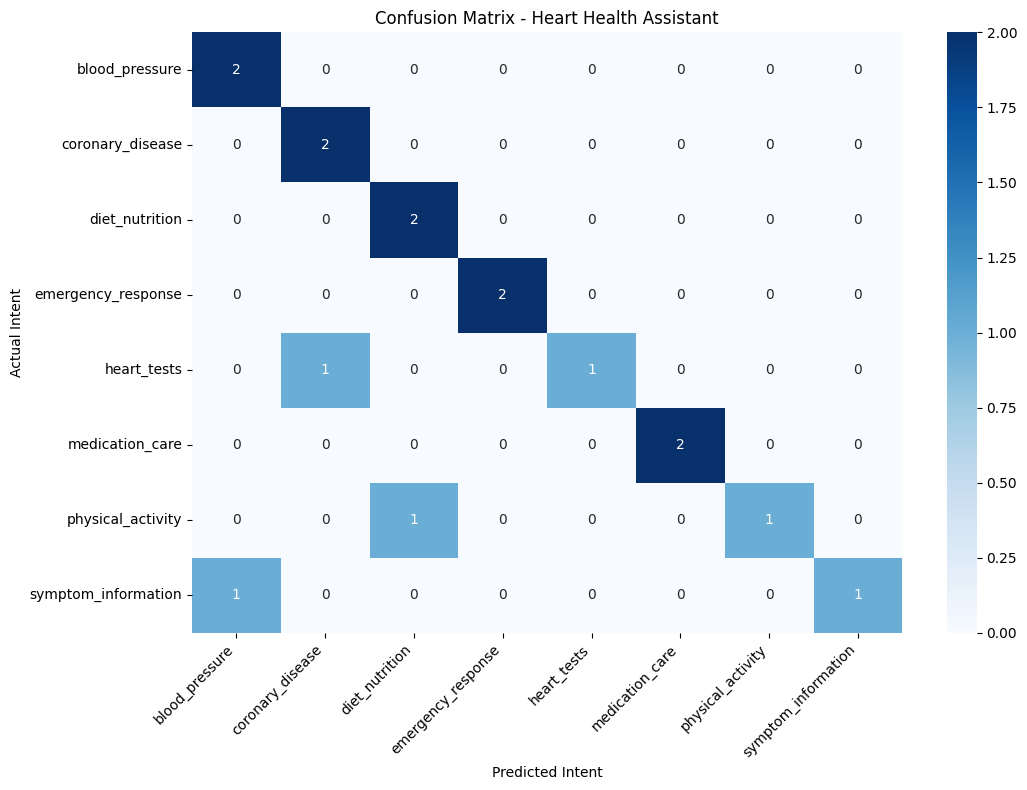

In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = list(model.named_steps["classifier"].classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(11, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix - Heart Health Assistant")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Build the heart-health knowledge base

In [9]:
knowledge_base = {
    "diet_nutrition": (
        "A heart-supportive eating pattern generally includes fruits, vegetables, "
        "whole grains, beans, nuts and suitable sources of protein. Limiting excess "
        "salt, trans fats and saturated fats may support cardiovascular health. "
        "For individual dietary needs, consult a qualified healthcare professional."
    ),
    "physical_activity": (
        "Regular physical activity can support heart and overall health. Many adults "
        "are advised to aim for at least 150 minutes of moderate-intensity activity "
        "per week, if appropriate for them. Start gradually and seek medical advice "
        "before starting if you have symptoms or a known health condition."
    ),
    "blood_pressure": (
        "Blood pressure measures the force of blood against artery walls. Persistently "
        "high blood pressure can increase cardiovascular risk. Monitoring, limiting "
        "excess sodium, physical activity and following a clinician's treatment plan "
        "can help manage it. A clinician should interpret individual readings."
    ),
    "coronary_disease": (
        "Coronary artery disease occurs when the arteries supplying the heart become "
        "narrowed or blocked, often due to plaque build-up. Risk factors can include "
        "high blood pressure, high cholesterol, smoking, diabetes and inactivity. "
        "A healthcare professional can assess personal risk and recommend care."
    ),
    "symptom_information": (
        "Possible heart-related symptoms include chest discomfort, shortness of breath, "
        "palpitations, unusual fatigue and swelling. These symptoms can have many causes. "
        "New, severe or worsening symptoms need prompt medical assessment. If symptoms "
        "suggest an emergency, call local emergency services immediately."
    ),
    "emergency_response": (
        "Possible heart attack warning signs include chest pain or pressure, discomfort "
        "in the arm, back, neck or jaw, shortness of breath, sweating or nausea. Call "
        "your local emergency number immediately. Do not drive yourself. Follow the "
        "dispatcher’s instructions. If a person is unresponsive and not breathing "
        "normally, call emergency services and begin CPR/use an AED if available and "
        "you are able, following dispatcher instructions."
    ),
    "medication_care": (
        "Take heart medicines only as prescribed. Do not stop, start or change a dose "
        "without speaking to the prescribing clinician or pharmacist. If you miss a "
        "dose or notice side effects, ask them for advice rather than doubling a dose."
    ),
    "heart_tests": (
        "An ECG records the heart's electrical activity. An echocardiogram uses "
        "ultrasound to create images of the heart. Stress tests assess the heart during "
        "increased activity, and blood tests may measure markers relevant to heart "
        "health. A clinician decides which tests are appropriate."
    )
}

print("Knowledge base created for", len(knowledge_base), "intent categories.")

Knowledge base created for 8 intent categories.


## 9. Implement reasoning rules

In [10]:
EMERGENCY_TERMS = [
    "severe chest pain", "chest pressure", "heart attack", "not breathing",
    "unresponsive", "collapsed", "cannot breathe", "can't breathe",
    "difficulty breathing", "shortness of breath", "sudden chest pain"
]

HEART_HEALTH_TERMS = [
    "heart", "cardiac", "cardiovascular", "chest", "blood pressure",
    "cholesterol", "artery", "arteries", "ecg", "palpitation",
    "heartbeat", "coronary", "hypertension", "heart attack"
]

def check_emergency(text):
    text = text.lower()
    return any(term in text for term in EMERGENCY_TERMS)

def is_heart_health_query(text):
    text = text.lower()
    return any(term in text for term in HEART_HEALTH_TERMS)

def apply_reasoning_rules(query, intent, confidence):
    # Rule 1: Emergency escalation always takes priority.
    if check_emergency(query):
        return (
            "EMERGENCY ALERT: This may be a medical emergency. "
            "Call your local emergency number immediately. Do not drive yourself. "
            "Follow the emergency dispatcher's instructions. This assistant cannot "
            "provide emergency diagnosis or treatment."
        )

    # Rule 2: Reject queries outside the assistant's domain.
    if not is_heart_health_query(query):
        return (
            "I can help with heart-health information, but this query appears to be "
            "outside my supported domain. Please ask a heart-health-related question."
        )

    # Rule 3: Ask for clarification when model confidence is low.
    if confidence < 0.35:
        return (
            "I am not confident enough to identify the intent of your question. "
            "Please rephrase it with more details, such as whether you are asking "
            "about diet, exercise, blood pressure, symptoms, medication or heart tests."
        )

    # Rule 4: Retrieve information only when a matching knowledge entry exists.
    if intent not in knowledge_base:
        return "I do not have reliable information for that topic in my knowledge base."

    # Rule 5: Provide educational information and medical-safety guidance.
    return knowledge_base[intent] + (
        "\n\nNote: This is general educational information, not a diagnosis. "
        "Consult a qualified healthcare professional for personal medical advice."
    )

print("Five reasoning rules implemented.")

Five reasoning rules implemented.


## 10. Integrate NLP, classification, reasoning and retrieval

In [11]:
def heart_health_assistant(query):
    if not isinstance(query, str) or not query.strip():
        return "Please enter a question."

    # Emergency rule is checked before machine-learning classification.
    if check_emergency(query):
        return apply_reasoning_rules(query, None, 1.0)

    if not is_heart_health_query(query):
        return apply_reasoning_rules(query, None, 0.0)

    processed = preprocess_text(query)

    if not processed.strip():
        return (
            "I could not identify enough meaningful words. Please rephrase "
            "your heart-health question."
        )

    probabilities = model.predict_proba([processed])[0]
    best_index = int(np.argmax(probabilities))
    predicted_intent = model.classes_[best_index]
    confidence = float(probabilities[best_index])

    response = apply_reasoning_rules(query, predicted_intent, confidence)

    return (
        f"Detected intent: {predicted_intent}\n"
        f"Confidence: {confidence:.2%}\n\n"
        f"Assistant: {response}"
    )

print(heart_health_assistant("What foods are good for heart health?"))

Detected intent: diet_nutrition
Confidence: 29.44%

Assistant: I am not confident enough to identify the intent of your question. Please rephrase it with more details, such as whether you are asking about diet, exercise, blood pressure, symptoms, medication or heart tests.


## 11. Test the assistant against the assignment's required cases

In [12]:
test_queries = [
    "What foods are good for heart health?",
    "Can walking improve cardiovascular fitness?",
    "How can I control high blood pressure?",
    "What is coronary artery disease?",
    "What are common symptoms of heart problems?",
    "What should I do if someone may be having a heart attack?",
    "Should I stop taking my heart medication?",
    "Why might a doctor recommend an ECG?",
    "How can I keep my ticker healthy through daily meals?",
    "How do I repair a laptop keyboard?",
    "Can you explain cardiac zorbital flux patterns?",
    "I have severe chest pain and difficulty breathing right now."
]

for i, query in enumerate(test_queries, 1):
    print("=" * 90)
    print(f"Test {i}: {query}")
    print(heart_health_assistant(query))
    print()

Test 1: What foods are good for heart health?
Detected intent: diet_nutrition
Confidence: 29.44%

Assistant: I am not confident enough to identify the intent of your question. Please rephrase it with more details, such as whether you are asking about diet, exercise, blood pressure, symptoms, medication or heart tests.

Test 2: Can walking improve cardiovascular fitness?
Detected intent: physical_activity
Confidence: 25.83%

Assistant: I am not confident enough to identify the intent of your question. Please rephrase it with more details, such as whether you are asking about diet, exercise, blood pressure, symptoms, medication or heart tests.

Test 3: How can I control high blood pressure?
Detected intent: blood_pressure
Confidence: 35.75%

Assistant: Blood pressure measures the force of blood against artery walls. Persistently high blood pressure can increase cardiovascular risk. Monitoring, limiting excess sodium, physical activity and following a clinician's treatment plan can help m

## 12. Interactive multi-query interface for Google Colab

In [13]:
import ipywidgets as widgets
from IPython.display import display, clear_output

chat_history = []

query_input = widgets.Text(
    placeholder="Ask a heart-health question...",
    description="Query:",
    layout=widgets.Layout(width="85%")
)

send_button = widgets.Button(
    description="Ask Assistant",
    button_style="success",
    icon="send"
)

clear_button = widgets.Button(
    description="Clear Chat",
    button_style="warning",
    icon="trash"
)

output = widgets.Output()

def on_send_clicked(button):
    query = query_input.value.strip()
    if not query:
        return

    response = heart_health_assistant(query)
    chat_history.append((query, response))
    query_input.value = ""

    with output:
        clear_output(wait=True)
        for user_query, assistant_response in chat_history:
            print("You:", user_query)
            print("Assistant:", assistant_response)
            print("-" * 80)

def on_clear_clicked(button):
    chat_history.clear()
    with output:
        clear_output()

send_button.on_click(on_send_clicked)
clear_button.on_click(on_clear_clicked)

display(widgets.VBox([
    widgets.HTML("<h3>Heart Health Information Assistant</h3>"),
    widgets.HTML("<p>Enter multiple heart-health questions below. For emergencies, contact local emergency services immediately.</p>"),
    widgets.HBox([query_input, send_button]),
    clear_button,
    output
]))

## 13. Conclusion

The Heart Health Information Assistant uses a labelled query corpus, a hierarchical taxonomy, domain concepts and relationships, NLP preprocessing, TF-IDF feature extraction and Logistic Regression classification. It evaluates the classifier using standard metrics and a confusion matrix. A knowledge base and rule-based reasoning layer handle information retrieval, emergency escalation, low-confidence inputs and unsupported queries. An interactive interface allows users to submit multiple queries in Google Colab.

**Limitation:** This is a small educational prototype. Its predictions and keyword-based emergency detection are not clinically validated and must not be used for diagnosis, treatment decisions or delaying emergency care.